# Biomomentum preprocessing with optional PID steady-force segmentation

Read each TXT file in `data/Biomomentum_Data/txts/`. Set `ENABLE_STEADY_STATE_SEGMENTATION = True` to export only the detected steady-force interval, or `False` to export the full recording, including loading and settling. Set `EXPORT_DURATION_S` to a number of seconds to limit either interval, or leave it as `None` to retain its full length. Run all cells in the **Dataprocess** environment with NumPy, pandas, Matplotlib, and IPython. Existing CSV files with matching names in `data/Biomomentum_Data/` are overwritten by the export cell.

Every output has exactly three ordered columns: **`Time, s`**, **`Indentation Position, mm`**, and **`Indentation Force, N`**. Use `Position (z), mm` as indentation and invert `Fz, N` so compression is positive. Reset **time only** to zero at the first retained sample; retain measured displacement and force, including PID oscillations. Do not filter, resample, or independently zero either measured signal.

A steady PID force can oscillate around its holding level. Detect the holding regime using a multi-period window mean and regression trend, with a separate allowance for force variation. Keep every sample within one continuous selected interval, including oscillation peaks and troughs. Review the plots before export. `_steady_state_manifest.csv` records the selected mode and original export boundaries, plus holding forces and detection settings when segmentation is enabled. Raw TXT files are read only.

Tables and plot labels retain two significant digits in the fractional part, ignoring leading fractional zeros (for example, 4.001234 becomes 4.0012 and 0.001234 becomes 0.0012). Exported force and displacement use two decimal places; timestamps and interval boundaries retain their precision to preserve 200 Hz sampling. Calculations use full precision before export. Rounding displacement to 0.01 mm can affect later fits of small creep changes.


In [10]:
import csv
import math
import sys

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

from pathlib import Path


def find_project_root(start):
    # Support running from the project root, data_process, or this notebook directory.
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'Biomomentum_Data' / 'txts').is_dir():
            return candidate
    raise FileNotFoundError('Could not find data/Biomomentum_Data/txts. Start the notebook within the project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data' / 'txts'
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data'
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from notebook_formatting import format_fractional_digits

pd.options.display.float_format = format_fractional_digits
from creep_force_preprocessing import segment_force_steady_state, extract_indentation_cycles

SAMPLING_HZ = 200.0
ENABLE_STEADY_STATE_SEGMENTATION = True  # False keeps the full recording.
EXPORT_DURATION_S = None  # Set to 60.0 for a 60-second export when available.
PID_STEADY_STATE_SETTINGS = dict(
    stability_window_s=2.0, stable_confirm_s=1.0, plateau_tail_s=5.0,
    level_tolerance_fraction=0.02, stable_std_fraction=0.05,
    stable_slope_fraction=0.01, release_guard_s=0.0, min_force_n=0.2,
)

# Used only with steady-state segmentation: positive delays, negative advances.
STEADY_START_OFFSET_S = 0.0
STEADY_END_OFFSET_S = 0.0

EXTRACT_COLUMNS = [
    'Time, s',
    'Position (z), mm',
    'Fz, N',
]

EXTRACT_COLUMNS_SIGNS = [
    1.0,
    1.0,
    -1.0,
]

OUTPUT_COLUMNS = [
    'Time, s',
    'Indentation Position, mm',
    'Indentation Force, N',
]

if len(EXTRACT_COLUMNS) != len(OUTPUT_COLUMNS):
    raise ValueError(f'EXTRACT_COLUMNS and OUTPUT_COLUMNS must have the same length. '
                     f'Found {len(EXTRACT_COLUMNS)} and {len(OUTPUT_COLUMNS)}.')

if len(EXTRACT_COLUMNS_SIGNS) != len(EXTRACT_COLUMNS):
    raise ValueError('EXTRACT_COLUMNS_SIGNS must contain one sign per extracted column.')
if any(not math.isfinite(sign) or sign not in (-1.0, 1.0) for sign in EXTRACT_COLUMNS_SIGNS):
    raise ValueError('Extraction signs must be finite and equal to +1 or -1.')
if EXTRACT_COLUMNS_SIGNS[0] != 1.0:
    raise ValueError('Keep the time sign at +1 so timestamps remain increasing.')

print(f'Input directory: {INPUT_DIR}')
print(f'Output directory: {OUTPUT_DIR}')
print(f'Steady-state segmentation: {ENABLE_STEADY_STATE_SEGMENTATION}')
print(f'Export duration: {EXPORT_DURATION_S} s')


def show_figure(fig):
    for axis in fig.axes:
        for coordinate in ('xaxis', 'yaxis', 'zaxis'):
            if hasattr(axis, coordinate):
                getattr(axis, coordinate).set_major_formatter(format_fractional_digits)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


Input directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data/txts
Output directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data
Steady-state segmentation: True
Export duration: None s


## Read data sections once

Read the export columns and native Fx/Fy/Fz together between `<DATA>` and `<END DATA>`, using column names rather than axis order. Validate finite numeric values and cache each recording in `recordings`. Derive signed export data from that cache; diagnostics retain the original sensor signs.


In [11]:
def read_biomomentum_txt(txt_path, columns=None, signs=None):
    columns = EXTRACT_COLUMNS if columns is None else columns
    signs = EXTRACT_COLUMNS_SIGNS if signs is None else signs
    if len(columns) != len(signs):
        raise ValueError('Each requested column must have one sign.')
    txt_path = Path(txt_path)
    rows = []
    in_data = False
    header = None
    block_rows = 0

    def invalid(line_number, message):
        return ValueError(f'{txt_path.name}:{line_number}: {message}')

    with txt_path.open('r', encoding='utf-8-sig', newline='') as handle:
        for line_number, fields in enumerate(csv.reader(handle, delimiter='\t'), start=1):
            fields = [field.strip() for field in fields]
            if not fields or not any(fields):
                continue
            marker = fields[0]
            if marker == '<DATA>':
                if in_data:
                    raise invalid(line_number, 'The previous data section is missing <END DATA>.')
                in_data, header, block_rows = True, None, 0
                continue
            if not in_data:
                continue
            if marker == '<END DATA>':
                if header is None or block_rows == 0:
                    raise invalid(line_number, 'The data section is empty.')
                in_data = False
                continue
            if header is None:
                header = fields
                missing = [column for column in columns if column not in header]
                if missing:
                    raise invalid(line_number, f'Missing columns: {missing}')
                if len(header) != len(set(header)):
                    raise invalid(line_number, 'The header contains duplicate column names.')
                column_indices = [header.index(column) for column in columns]
                continue
            if len(fields) != len(header):
                raise invalid(line_number, f'Expected {len(header)} columns, found {len(fields)}.')
            selected = [fields[index] for index in column_indices]
            row = []
            for column, sign, value in zip(columns, signs, selected):
                try:
                    numeric_value = float(value)
                except ValueError as exc:
                    raise invalid(line_number, f'{column} contains a nonnumeric value: {value!r}') from exc
                if not math.isfinite(numeric_value):
                    raise invalid(line_number, f'{column} contains a nonfinite value: {value!r}')
                row.append(sign * numeric_value)
            rows.append(row)
            block_rows += 1

    if in_data:
        raise ValueError(f'{txt_path.name}: Reached the end of the file without finding <END DATA>.')
    if not rows:
        raise ValueError(f'{txt_path.name}: No valid <DATA> section was found.')
    return rows


## Validate all input files

Read every TXT before selecting intervals or writing CSVs. Each recording is treated as one loading-and-hold interval. Require continuous 200 Hz timestamps; multiple concatenated data blocks with restarted times or missing samples raise an error instead of being joined into a false continuous record.

In [12]:
txt_files = sorted(
    path for path in INPUT_DIR.iterdir()
    if path.is_file() and path.suffix.lower() == '.txt'
)
if not txt_files:
    raise FileNotFoundError(f'No TXT files were found in the input directory: {INPUT_DIR}')

# Read each TXT once, retaining native force axes alongside the export columns.
native_columns = list(dict.fromkeys([*EXTRACT_COLUMNS, 'Fx, N', 'Fy, N', 'Fz, N']))
recordings = {
    path: pd.DataFrame(read_biomomentum_txt(path, native_columns, [1.0] * len(native_columns)),
                       columns=native_columns)
    for path in txt_files
}
extracted = [(path, native[EXTRACT_COLUMNS].to_numpy() * EXTRACT_COLUMNS_SIGNS)
             for path, native in recordings.items()]


## Select the export interval

With `ENABLE_STEADY_STATE_SEGMENTATION = False`, retain every sample from the first through the last timestamp. Skip PID detection, its settings, and both `STEADY_*_OFFSET_S` adjustments. The selection plots show the full recording. Continuous 200 Hz timestamps and finite sensor values are still required.

With `ENABLE_STEADY_STATE_SEGMENTATION = True`, apply the following PID steady-force selection. In either mode, set `EXPORT_DURATION_S` to a multiple of 0.005 s to retain that many seconds from the first selected sample. For example, `60.0` yields 12,000 rows with the last time value at 59.995 s. `None` retains the whole selected interval. The current steady-force intervals are shorter than 60 s, so choose a shorter duration in steady-state mode. A requested duration longer than the selected interval raises an error before export.

Estimate the holding force from the median of the last **5 s**. Over a full trailing **2 s** window, require the mean within **2%** of that level, a force standard deviation no greater than **5%** of the level, and an absolute regression slope no greater than **1% of the holding force per second**. The 2 s window spans several of the approximately 0.6 s PID oscillations in these recordings; the variation allowance does not require a flat instantaneous force. Adjust `PID_STEADY_STATE_SETTINGS` if the controller oscillation period or amplitude changes.

Confirm the conditions continuously for **1 s**, and start at the first qualifying window endpoint in that run. Retain one continuous interval through the recording end, or stop earlier at the beginning of a later sustained loss of stability. Brief fluctuations and all bounded oscillation samples remain. No pointwise force threshold is applied to exported rows. These TXT recordings contain no release segment, so `release_guard_s` is zero; if future recordings include unloading, bound the hold before applying this detector.

After automatic detection, `STEADY_START_OFFSET_S` and `STEADY_END_OFFSET_S` shift the start and end boundaries for every recording. Positive values delay a boundary; negative values advance it. For example, start `-0.5` and end `-1.0` include 0.5 s earlier and stop 1 s earlier than the detected interval. Both default to `0.0`. Apply offsets before limiting the interval with `EXPORT_DURATION_S`. Manual extensions can include non-steady force. The adjusted interval must remain within the recording, contain at least two samples, and contain no missing sensor values; invalid adjustments raise an error rather than being clipped. Selection uses the existing 200 Hz grid: the first retained timestamp is at or after the adjusted start, and the end is exclusive. Rerun selection and plotting after changing offsets. The manifest records detected boundaries, offsets, adjusted boundaries, and final export boundaries.

The rolling statistics select boundaries only. Force and displacement remain unchanged, with their original alignment and amplitude. A recording without a confirmed steady interval raises an error before any exports are written.

The selection plots show the full displacement profile above the corresponding full force profile for each recording, sharing the original time axis. Green shading marks the final export mask after applying boundary offsets and any `EXPORT_DURATION_S` limit; vertical lines mark its start and exclusive end.


In [13]:
if EXPORT_DURATION_S is not None and (
        not np.isfinite(EXPORT_DURATION_S) or EXPORT_DURATION_S < 2 / SAMPLING_HZ
        or not np.isclose(EXPORT_DURATION_S * SAMPLING_HZ,
                          round(EXPORT_DURATION_S * SAMPLING_HZ), rtol=0, atol=1e-8)):
    raise ValueError('EXPORT_DURATION_S must be at least two samples and a multiple of the sampling interval.')
if ENABLE_STEADY_STATE_SEGMENTATION and not np.isfinite(
        [STEADY_START_OFFSET_S, STEADY_END_OFFSET_S]).all():
    raise ValueError('Steady-state boundary offsets must be finite seconds.')

segment_label = 'steady-force' if ENABLE_STEADY_STATE_SEGMENTATION else 'full-recording'
steady_extracted = []
segmentation_results = []
manifest_rows = []
for txt_path, rows in extracted:
    values = np.asarray(rows, dtype=float)
    sync = pd.DataFrame({
        'time_s': values[:, 0],
        'displacement_mm': values[:, 1],
        'force_n': values[:, 2],
    })
    cycle = pd.DataFrame([{
        'cycle': 1, 'onset_s': values[0, 0],
        'release_s': values[-1, 0] + 1.0 / SAMPLING_HZ,
    }])
    try:
        bounds = (segment_force_steady_state(sync, cycle, **PID_STEADY_STATE_SETTINGS)
                  if ENABLE_STEADY_STATE_SEGMENTATION else cycle)
        if ENABLE_STEADY_STATE_SEGMENTATION:
            bounds['detected_steady_start_s'] = bounds.steady_start_s
            bounds['detected_steady_end_s'] = bounds.steady_end_s
            bounds['steady_start_s'] += STEADY_START_OFFSET_S
            bounds['steady_end_s'] += STEADY_END_OFFSET_S
        event = bounds.iloc[0]
        export_start = event.steady_start_s if ENABLE_STEADY_STATE_SEGMENTATION else event.onset_s
        export_end = event.steady_end_s if ENABLE_STEADY_STATE_SEGMENTATION else event.release_s
        if (not np.isfinite([export_start, export_end]).all()
                or export_start < event.onset_s or export_end > event.release_s
                or export_start >= export_end):
            raise ValueError('Adjusted export boundaries must lie within the recording and start before the end.')
        export_bounds = bounds
        if EXPORT_DURATION_S is not None:
            times = sync.time_s.to_numpy()
            first = np.searchsorted(times, export_start)
            available = np.searchsorted(times, export_end) - first
            samples = round(EXPORT_DURATION_S * SAMPLING_HZ)
            if available < samples:
                raise ValueError(f'Only {available / SAMPLING_HZ:g} s available; '
                                 f'EXPORT_DURATION_S requests {EXPORT_DURATION_S:g} s.')
            next_sample = first + samples
            export_end = (min(times[next_sample], export_end) if next_sample < len(times)
                          else export_end)
            export_bounds = bounds.copy()
            export_bounds['steady_end_s' if ENABLE_STEADY_STATE_SEGMENTATION else 'release_s'] = export_end
        _, frame = extract_indentation_cycles(
            sync, export_bounds, sampling_hz=SAMPLING_HZ,
            steady_only=ENABLE_STEADY_STATE_SEGMENTATION, time_origin_s=None,
        )[0]
    except ValueError as exc:
        raise ValueError(f'{txt_path.name}: {exc}') from exc
    steady_extracted.append((txt_path, frame))
    segmentation_results.append(dict(path=txt_path, sync=sync, bounds=bounds, frame=frame,
                                     export_start_s=export_start, export_end_s=export_end))
    manifest_rows.append({
        'file': f'{txt_path.stem}.csv',
        'source_txt': str(txt_path.relative_to(PROJECT_ROOT)),
        'steady_state_segmentation': ENABLE_STEADY_STATE_SEGMENTATION,
        'export_scope': 'steady_force_only' if ENABLE_STEADY_STATE_SEGMENTATION else 'full_load',
        'export_start_s': export_start,
        'export_end_s': export_end,
        'original_start_s': values[0, 0], 'original_last_sample_s': values[-1, 0],
        'rows': len(frame), 'duration_s': frame[OUTPUT_COLUMNS[0]].iloc[-1],
        'sampling_hz': SAMPLING_HZ,
        'force_std_n': frame[OUTPUT_COLUMNS[2]].std(ddof=0),
        'force_peak_to_peak_n': np.ptp(frame[OUTPUT_COLUMNS[2]].to_numpy()),
        'position_sign': EXTRACT_COLUMNS_SIGNS[1], 'force_sign': EXTRACT_COLUMNS_SIGNS[2],
        **({
            'detected_steady_start_s': event.detected_steady_start_s,
            'detected_steady_end_s': event.detected_steady_end_s,
            'steady_start_offset_s': STEADY_START_OFFSET_S,
            'steady_end_offset_s': STEADY_END_OFFSET_S,
            'steady_start_s': event.steady_start_s, 'steady_end_s': event.steady_end_s,
            'steady_force_n': event.steady_force_n,
            **{f'pid_{key}': value for key, value in PID_STEADY_STATE_SETTINGS.items()},
        } if ENABLE_STEADY_STATE_SEGMENTATION else {}),
    })

steady_summary = pd.DataFrame(manifest_rows)
display(steady_summary[['file', 'export_scope', 'export_start_s', 'export_end_s',
                        'force_std_n', 'rows', 'duration_s']])

,file,export_scope,export_start_s,export_end_s,force_std_n,rows,duration_s
0,Creep_1.csv,steady_force_only,3.82,61.20,0.026,11476,57.38
1,Creep_2.csv,steady_force_only,3.85,61.30,0.013,11490,57.45
2,Creep_3.csv,steady_force_only,3.81,61.20,0.020,11477,57.38
3,Creep_4.csv,steady_force_only,3.83,60.70,0.034,11373,56.86
4,Creep_5.csv,steady_force_only,3.88,60.70,0.032,11365,56.82
5,Creep_6.csv,steady_force_only,3.81,61.20,0.014,11479,57.39


## Native force diagnostics: trajectory, deviation, and resultant force

Reuse Fx, Fy, and Fz from every loaded TXT data row in acquisition order, using the full recording rather than the export mask. Subtract the first recorded three-axis force vector from the entire recording for this visualization only. The first sample must be unloaded for this to represent the sensor bias; a loaded first sample would remove real preload. Keep the sensor signs, so compression points along negative Z. Do not apply the positive-compression extraction signs. No filtering, interpolation, synchronization, or resampling is used. Existing force/displacement extraction and CSV exports are unchanged.

The dashed ideal trajectory runs from the origin along `[0, 0, -1]`, extended to the largest measured force magnitude (at least 1 N). All axes have equal scale in newtons; measured vectors are not normalized. Run the loading and interval-selection cells first. All four panels reuse the loaded native force samples.

### Indentation force deviation angle and cycle statistics

For each bias-corrected native force vector, compute the angle between the componentwise absolute measured and ideal vectors as `theta = degrees(atan2(sqrt(Fx**2 + Fy**2), abs(Fz)))`. This is equivalent to `acos(abs(Fz) / ||F||)` for a nonzero vector and ranges from 0 to 90 degrees. Both positive and negative Z are 0 degrees, and transverse force is 90 degrees, so retraction does not turn a small axis deviation into an angle near 180 degrees. Taking absolute values of Fx and Fy does not change their squared sum. This measures force-axis deviation; it does not directly measure the displacement direction or indenter orientation.

Set `MIN_ANGLE_FORCE_N` below to change the default 0.2 N magnitude threshold. Samples below the threshold receive `NaN` because direction is unreliable near zero force; no force values are smoothed or resampled. The time plot uses all native timestamps and leaves gaps for excluded angles.

Each Biomomentum TXT recording is treated as one cycle, using its full loading-and-hold recording rather than the export mask. Its cycle mean is the arithmetic mean of valid native sample angles, rather than the angle of an averaged force vector. `cycle_deviation_summary` reports the mean for each file; `overall_deviation_summary` reports the mean and sample standard deviation of those cycle means, with equal weight per TXT file.

The across-cycle standard deviation uses `ddof=1` (sample standard deviation). A cycle without any angles above the threshold has a `NaN` mean and is excluded from across-cycle mean/std; total and valid cycle counts expose these exclusions. The across-cycle standard deviation is `NaN` with fewer than two valid cycles. These diagnostic tables do not alter the export CSV schema.

### Steady resultant force variation

Treat each Biomomentum TXT as one cycle and use its `export_start_s <= time_s < export_end_s` interval from `segmentation_results`. Steady-state variation is shown only when segmentation is enabled; full native diagnostics remain available in either mode. These are the selected steady-state export intervals after the configured boundary offsets and any `EXPORT_DURATION_S` limit; manually extended boundaries may include non-steady samples. Rerun loading, selection, and this cell after changing input files, baselines, or interval settings.

The lower-left panel shows the full native resultant force with selected intervals shaded. The lower-right panel overlays `delta_force_n = resultant_force_n - mean(resultant_force_n)` for each selected cycle, with time zero at its first retained native sample. `steady_resultant_summary` reports the cycle mean, sample standard deviation (`ddof=1`), and peak-to-peak range (`max - min`), all in newtons. Subtracting the mean changes only the lower plot's reference, not the measured force. Raw data, deviation-angle summaries, and CSV exports are unchanged.


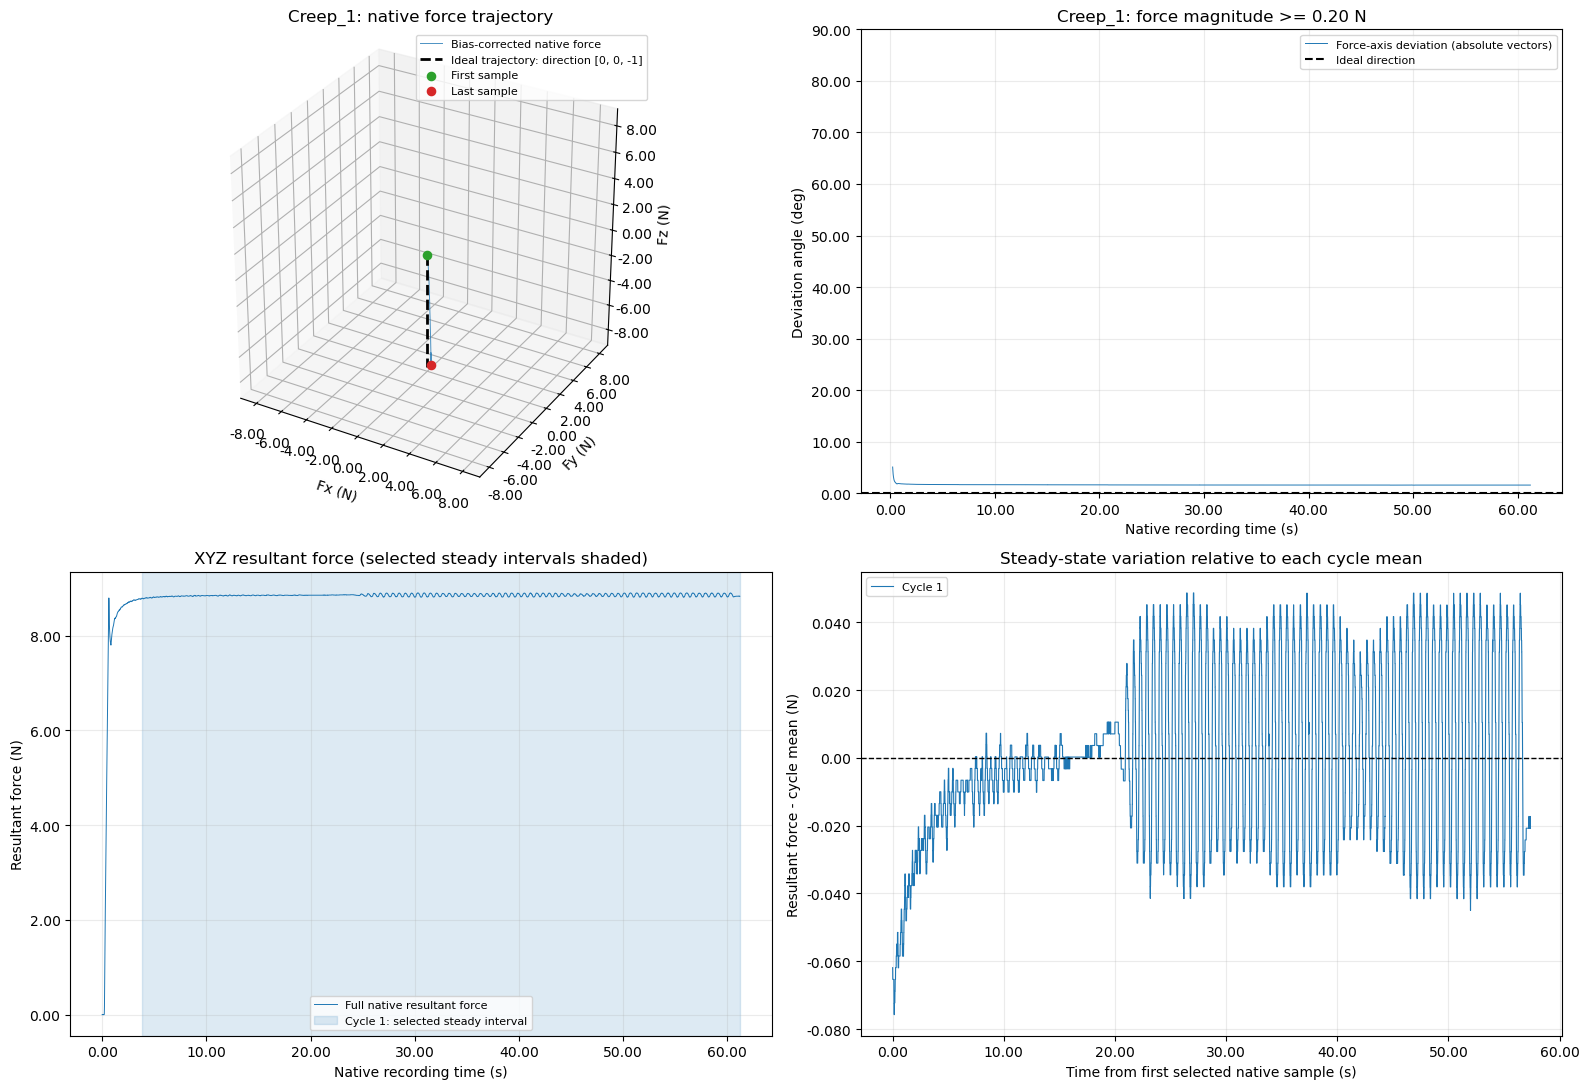

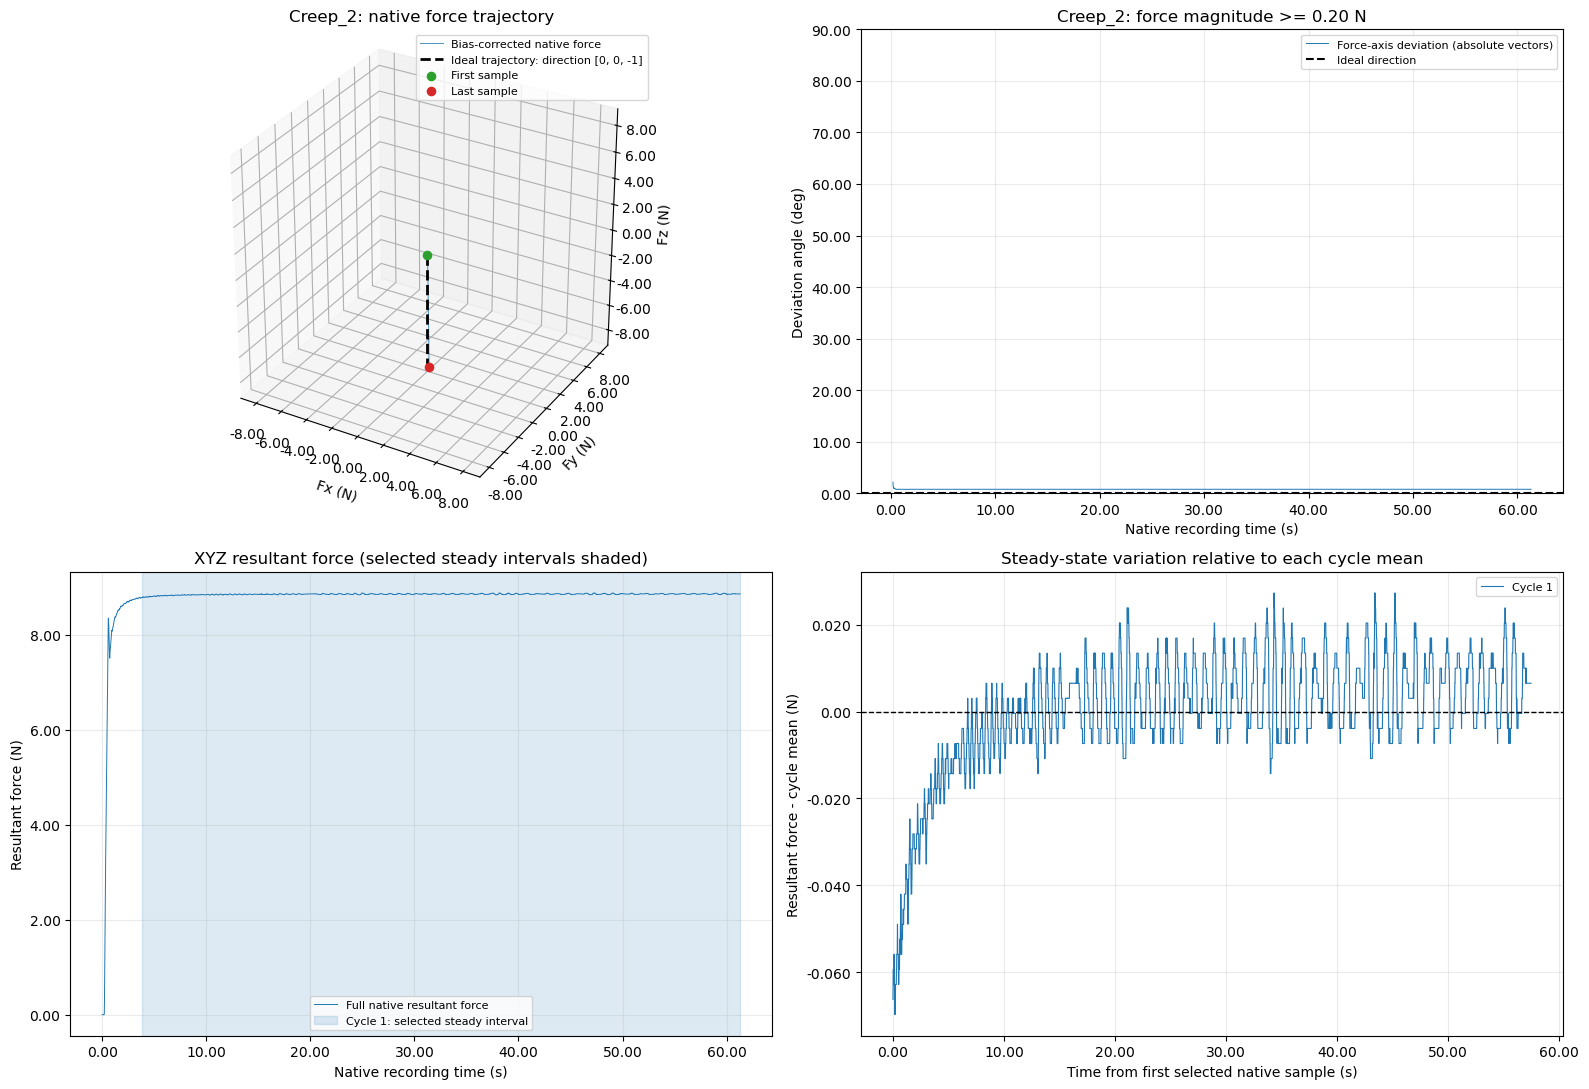

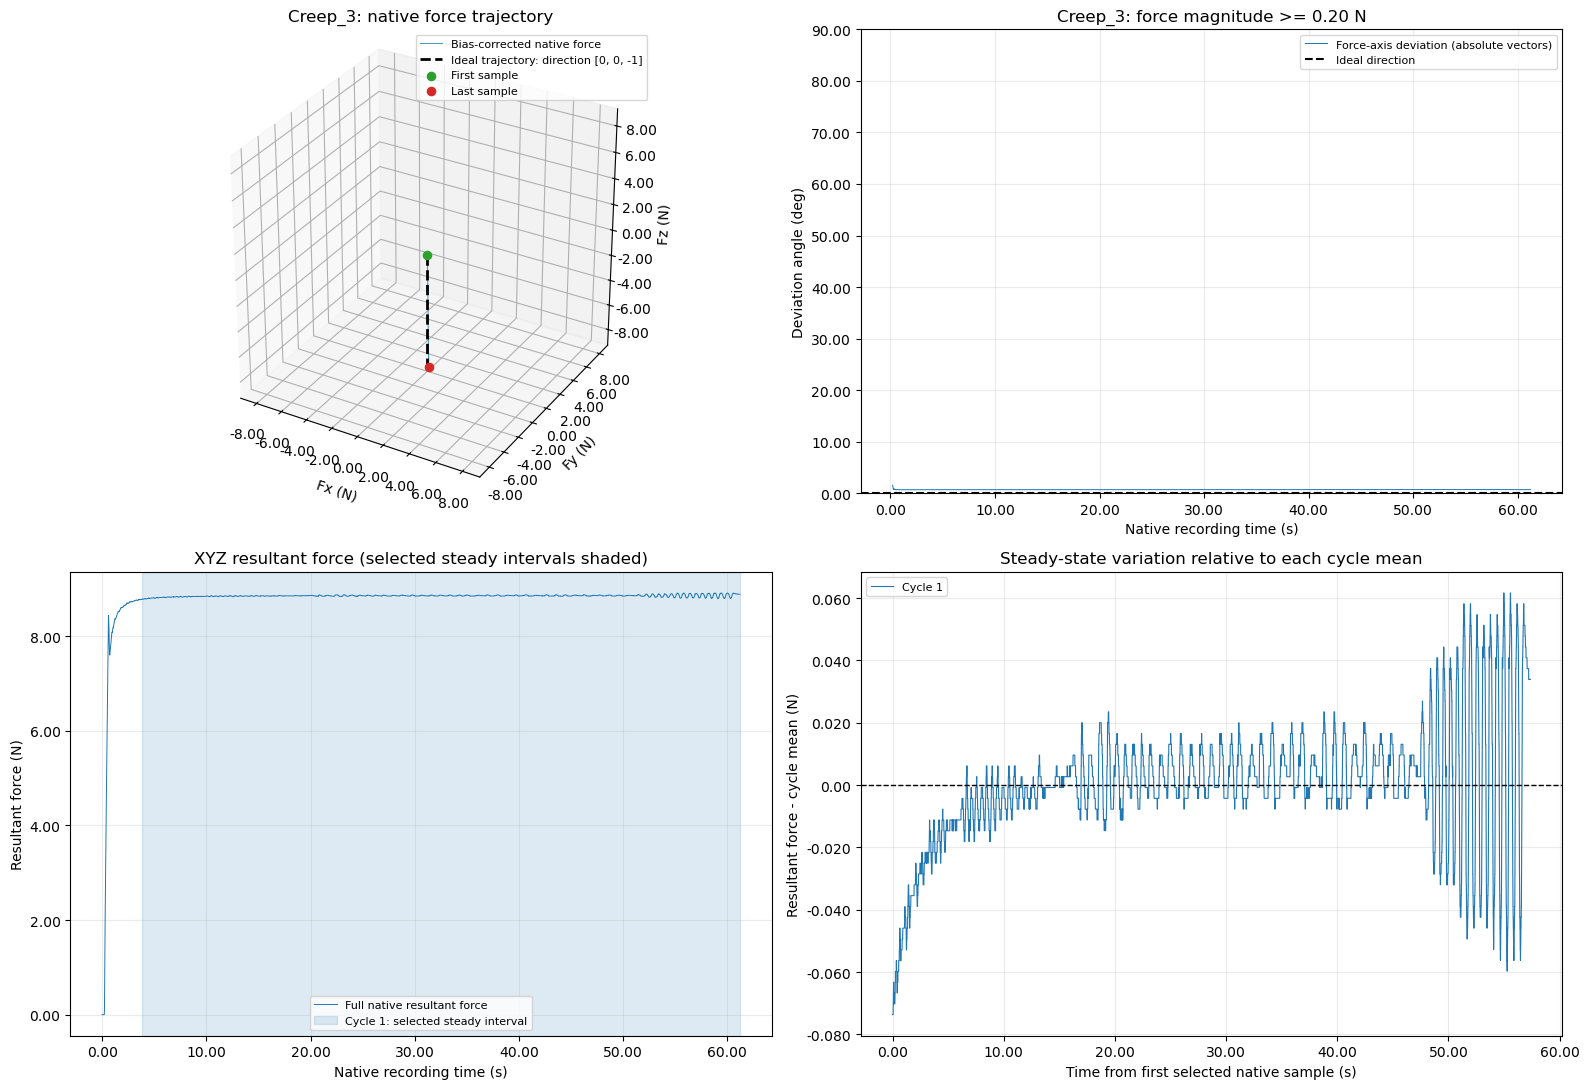

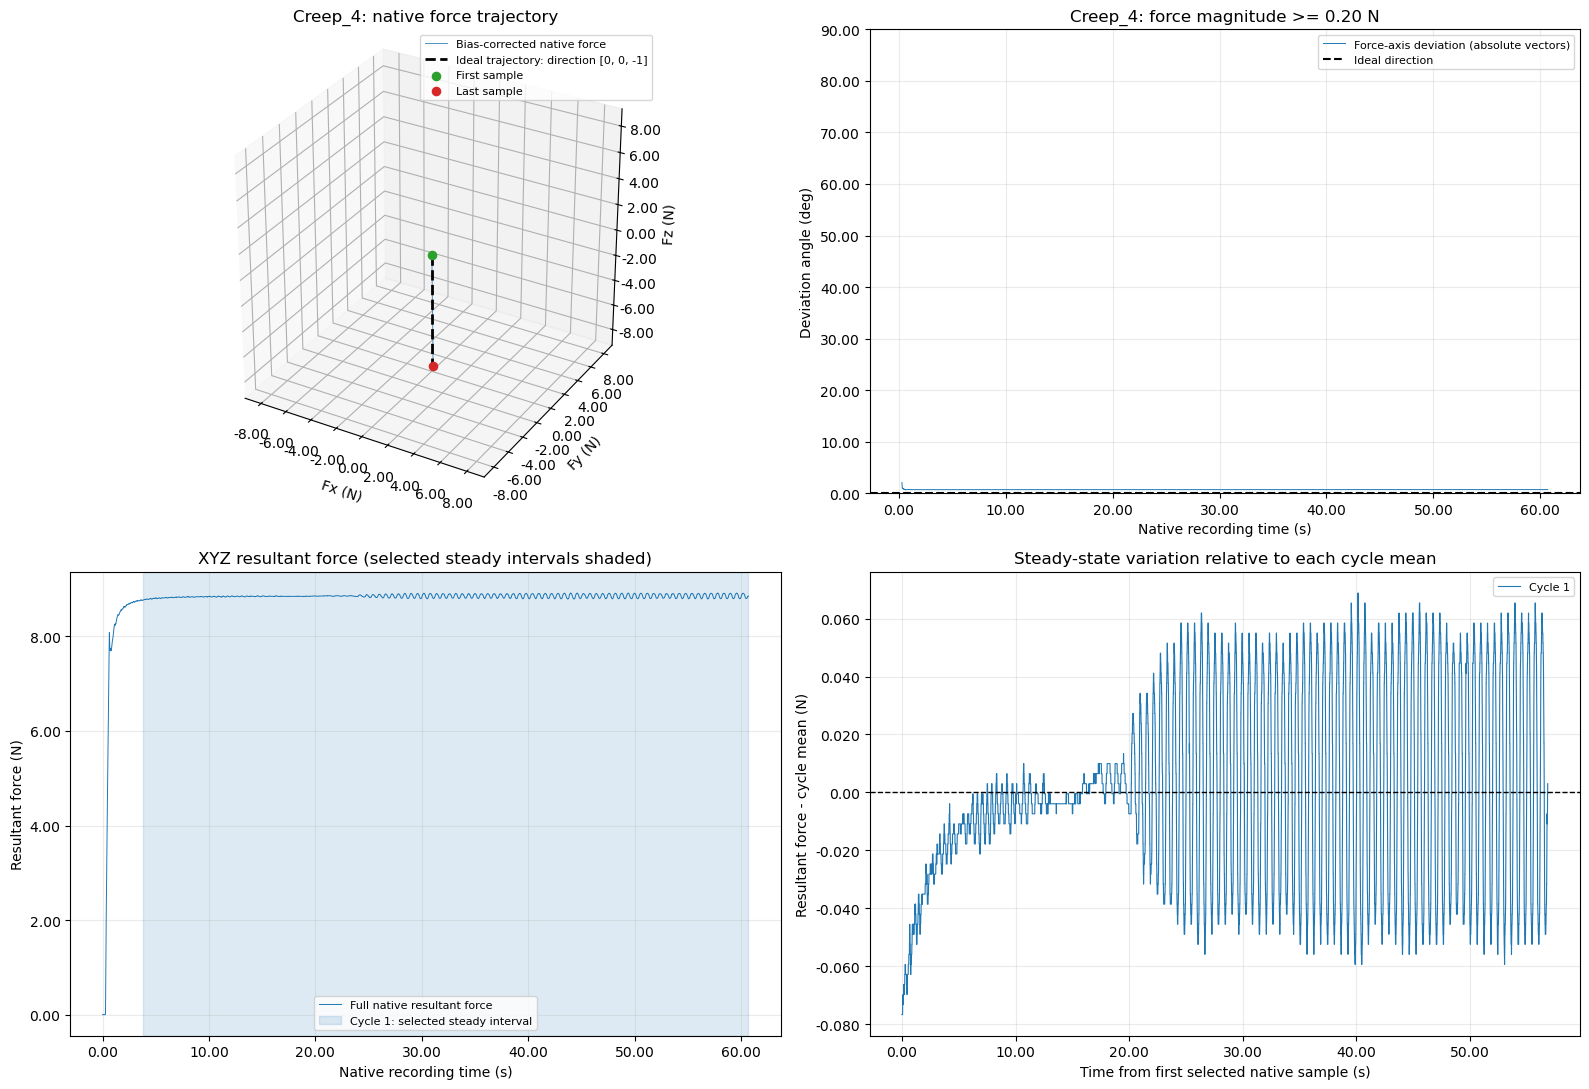

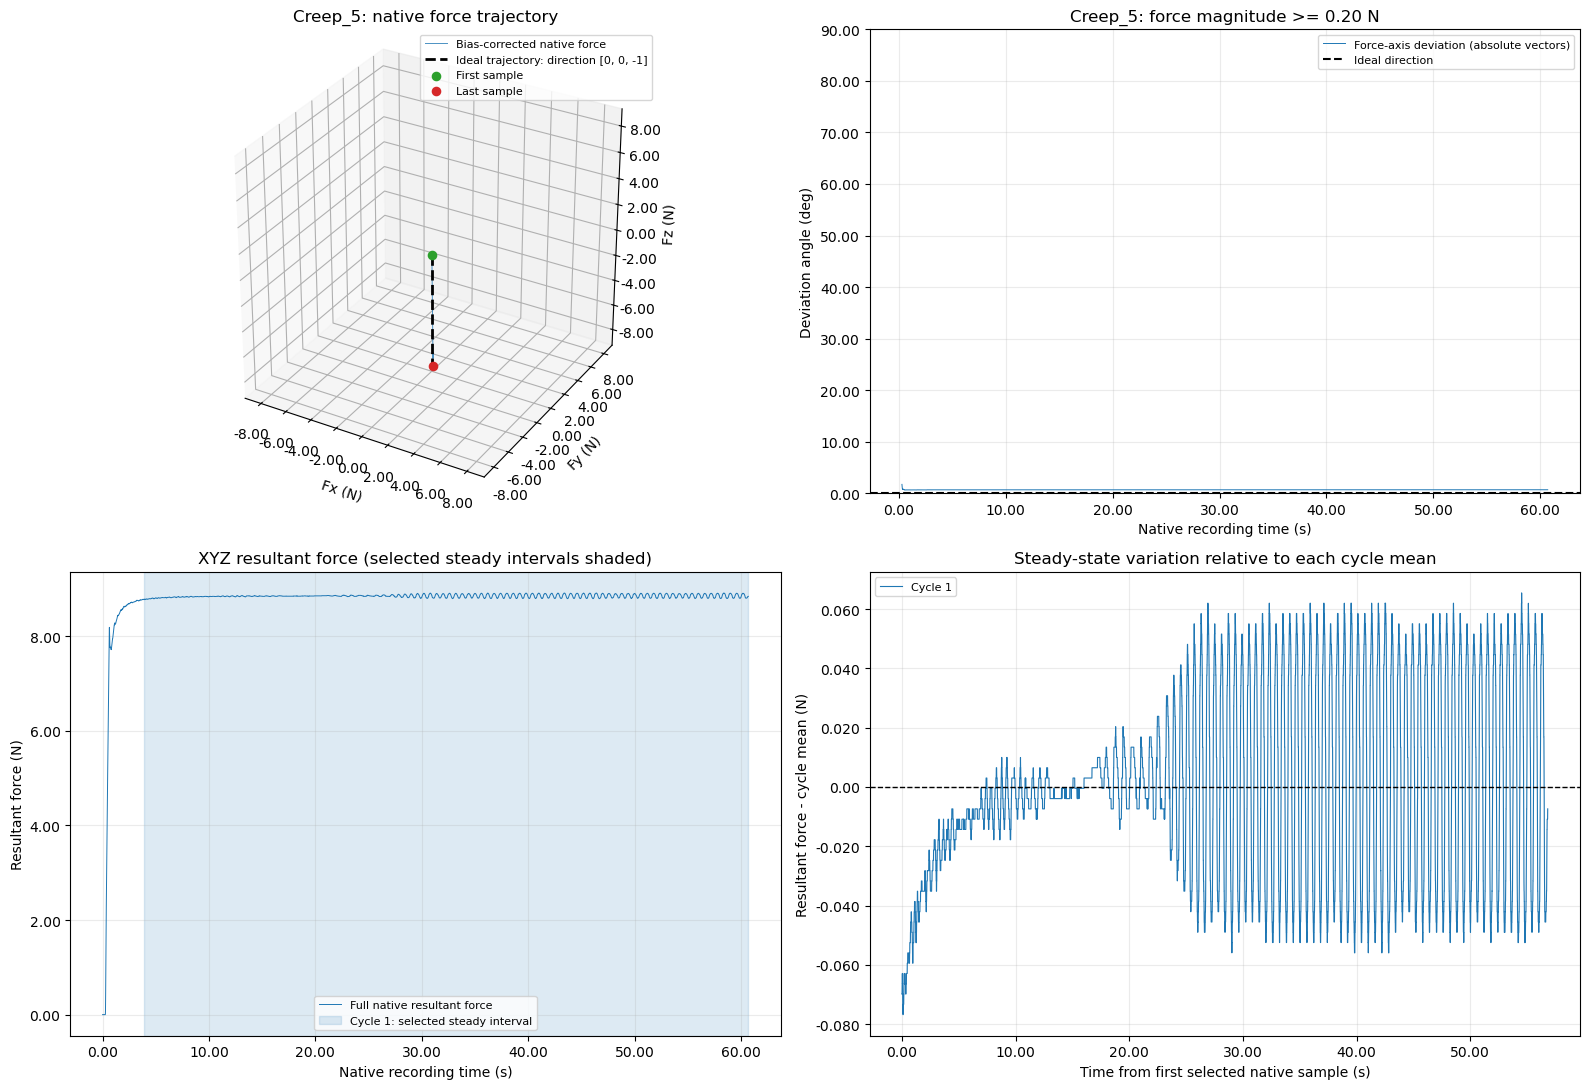

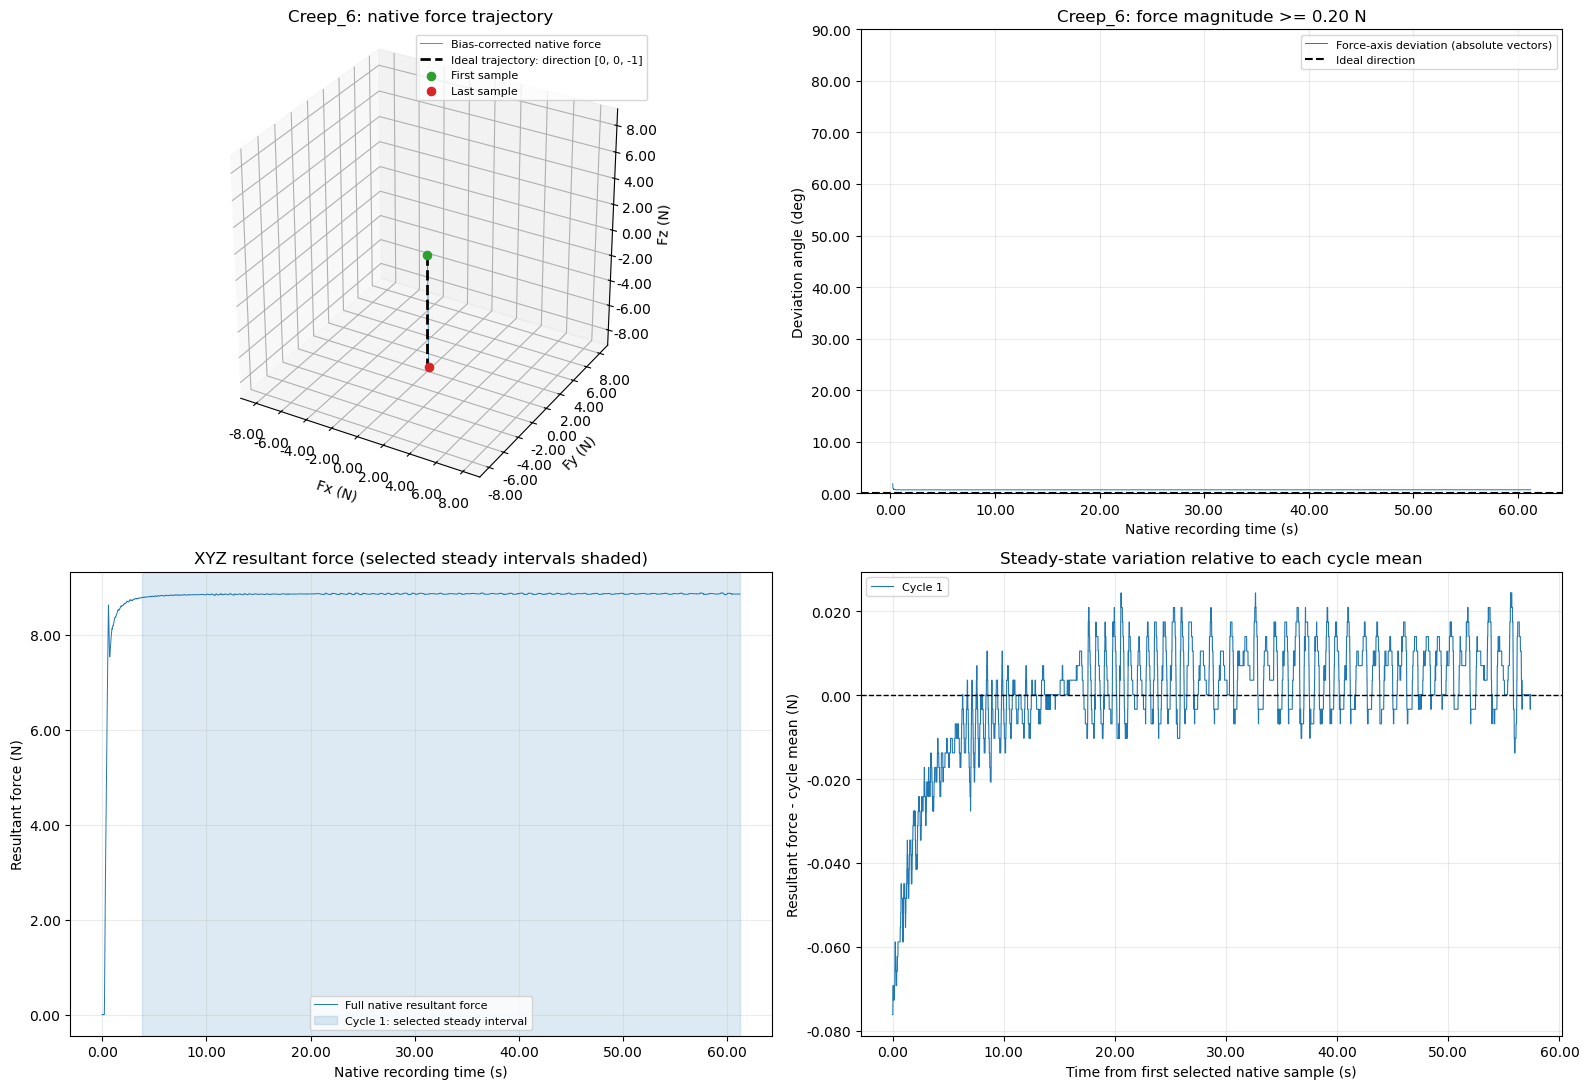

,trial,cycle,start_s,last_sample_s,native_samples,valid_angle_samples,mean_deviation_deg
0,Creep_1,1,0.00,61.20,12240,12195,1.62
1,Creep_2,1,0.00,61.30,12260,12216,0.77
2,Creep_3,1,0.00,61.20,12240,12195,0.70
3,Creep_4,1,0.00,60.70,12140,12083,0.70
4,Creep_5,1,0.00,60.70,12140,12083,0.67
5,Creep_6,1,0.00,61.20,12240,12195,0.67


,total_cycles,valid_cycles,mean_of_cycle_means_deg,std_of_cycle_means_deg
0,6,6,0.85,0.38


,trial,cycle,start_s,end_s,native_samples,mean_resultant_force_n,std_resultant_force_n,peak_to_peak_resultant_force_n
0,Creep_1,1,3.82,61.20,11476,8.85,0.026,0.12
1,Creep_2,1,3.85,61.30,11490,8.85,0.013,0.097
2,Creep_3,1,3.81,61.20,11477,8.85,0.020,0.14
3,Creep_4,1,3.83,60.70,11373,8.85,0.034,0.15
4,Creep_5,1,3.88,60.70,11365,8.85,0.032,0.14
5,Creep_6,1,3.81,61.20,11479,8.85,0.014,0.10


In [14]:
MIN_ANGLE_FORCE_N = 0.2
if not np.isfinite(MIN_ANGLE_FORCE_N) or MIN_ANGLE_FORCE_N <= 0:
    raise ValueError('MIN_ANGLE_FORCE_N must be finite and positive.')
angle_rows = []
resultant_rows = []

for result in segmentation_results:
    txt_path = result['path']
    name = txt_path.stem
    native = recordings[txt_path]
    force_xyz = native[['Fx, N', 'Fy, N', 'Fz, N']].to_numpy(copy=True)
    force_xyz -= force_xyz[0].copy()
    force_magnitude = np.linalg.norm(force_xyz, axis=1)
    deviation_deg = np.degrees(np.arctan2(
        np.hypot(force_xyz[:, 0], force_xyz[:, 1]), np.abs(force_xyz[:, 2]),
    ))
    deviation_deg[force_magnitude < MIN_ANGLE_FORCE_N] = np.nan
    angle_times = native['Time, s'].to_numpy()
    trace = pd.DataFrame({
        'time_s': angle_times, 'resultant_force_n': force_magnitude,
    })
    valid_angles = deviation_deg[np.isfinite(deviation_deg)]
    angle_rows.append({
        'trial': name, 'cycle': 1,
        'start_s': angle_times[0], 'last_sample_s': angle_times[-1],
        'native_samples': len(angle_times), 'valid_angle_samples': len(valid_angles),
        'mean_deviation_deg': valid_angles.mean() if len(valid_angles) else np.nan,
    })
    extent = max(1.0, float(force_magnitude.max()))
    fig = plt.figure(figsize=(16, 11))
    ax = fig.add_subplot(221, projection='3d')
    ax.plot(*force_xyz.T, lw=0.7, alpha=0.8, label='Bias-corrected native force')
    ax.plot([0, 0], [0, 0], [0, -extent], 'k--', lw=2,
            label='Ideal trajectory: direction [0, 0, -1]')
    ax.scatter(*force_xyz[0], color='tab:green', s=35, label='First sample')
    ax.scatter(*force_xyz[-1], color='tab:red', s=35, label='Last sample')
    ax.set(xlabel='Fx (N)', ylabel='Fy (N)', zlabel='Fz (N)',
           title=f'{name}: native force trajectory',
           xlim=(-extent, extent), ylim=(-extent, extent), zlim=(-extent, extent))
    ax.set_box_aspect((1, 1, 1))
    ax.legend(fontsize=8)
    angle_ax = fig.add_subplot(222)
    angle_ax.plot(angle_times, deviation_deg, lw=0.7, label='Force-axis deviation (absolute vectors)')
    angle_ax.axhline(0, color='black', ls='--', label='Ideal direction')
    angle_ax.set(xlabel='Native recording time (s)', ylabel='Deviation angle (deg)', ylim=(0, 90),
                 title=f'{name}: force magnitude >= {format_fractional_digits(MIN_ANGLE_FORCE_N)} N')
    angle_ax.grid(True, alpha=0.25)
    angle_ax.legend(fontsize=8)
    resultant_ax = fig.add_subplot(223)
    variation_ax = fig.add_subplot(224)
    resultant_ax.plot(trace.time_s, trace.resultant_force_n, lw=0.7,
                      color='tab:blue', label='Full native resultant force')
    if ENABLE_STEADY_STATE_SEGMENTATION:
        for event in result['bounds'].itertuples():
            cycle = int(event.cycle)
            start, end = result['export_start_s'], result['export_end_s']
            selected = trace.loc[(trace.time_s >= start) & (trace.time_s < end)]
            if len(selected) < 2 or not np.isfinite(selected.resultant_force_n).all():
                raise ValueError(f'{name} cycle {cycle}: Need at least two finite native force samples.')
            resultant = selected.resultant_force_n.to_numpy()
            mean_force = resultant.mean()
            delta_force = resultant - mean_force
            resultant_rows.append({
                'trial': name, 'cycle': cycle, 'start_s': start, 'end_s': end,
                'native_samples': len(selected),
                'mean_resultant_force_n': mean_force,
                'std_resultant_force_n': resultant.std(ddof=1),
                'peak_to_peak_resultant_force_n': np.ptp(resultant),
            })
            label = f'Cycle {cycle}'
            line, = variation_ax.plot(selected.time_s - selected.time_s.iloc[0], delta_force,
                                     lw=0.8, label=label)
            resultant_ax.axvspan(start, end, color=line.get_color(), alpha=0.15, label=f'{label}: selected steady interval')
    resultant_ax.set(title='XYZ resultant force (selected steady intervals shaded)',
                xlabel='Native recording time (s)', ylabel='Resultant force (N)')
    if not ENABLE_STEADY_STATE_SEGMENTATION:
        variation_ax.text(0.5, 0.5, 'Enable steady-state segmentation to inspect steady variation.',
                          ha='center', va='center', transform=variation_ax.transAxes)
    variation_ax.axhline(0, color='black', ls='--', lw=1)
    variation_ax.set(title='Steady-state variation relative to each cycle mean',
                xlabel='Time from first selected native sample (s)',
                ylabel='Resultant force - cycle mean (N)')
    for axis in (resultant_ax, variation_ax):
        axis.grid(True, alpha=0.25)
        if axis.get_legend_handles_labels()[0]:
            axis.legend(fontsize=8)
    show_figure(fig)

cycle_deviation_summary = pd.DataFrame(angle_rows)
display(cycle_deviation_summary)
cycle_means = cycle_deviation_summary['mean_deviation_deg']
overall_deviation_summary = pd.DataFrame([{
    'total_cycles': len(cycle_means), 'valid_cycles': int(cycle_means.count()),
    'mean_of_cycle_means_deg': cycle_means.mean(),
    'std_of_cycle_means_deg': cycle_means.std(ddof=1),
}])
display(overall_deviation_summary)

steady_resultant_summary = pd.DataFrame(resultant_rows)
if ENABLE_STEADY_STATE_SEGMENTATION:
    display(steady_resultant_summary)


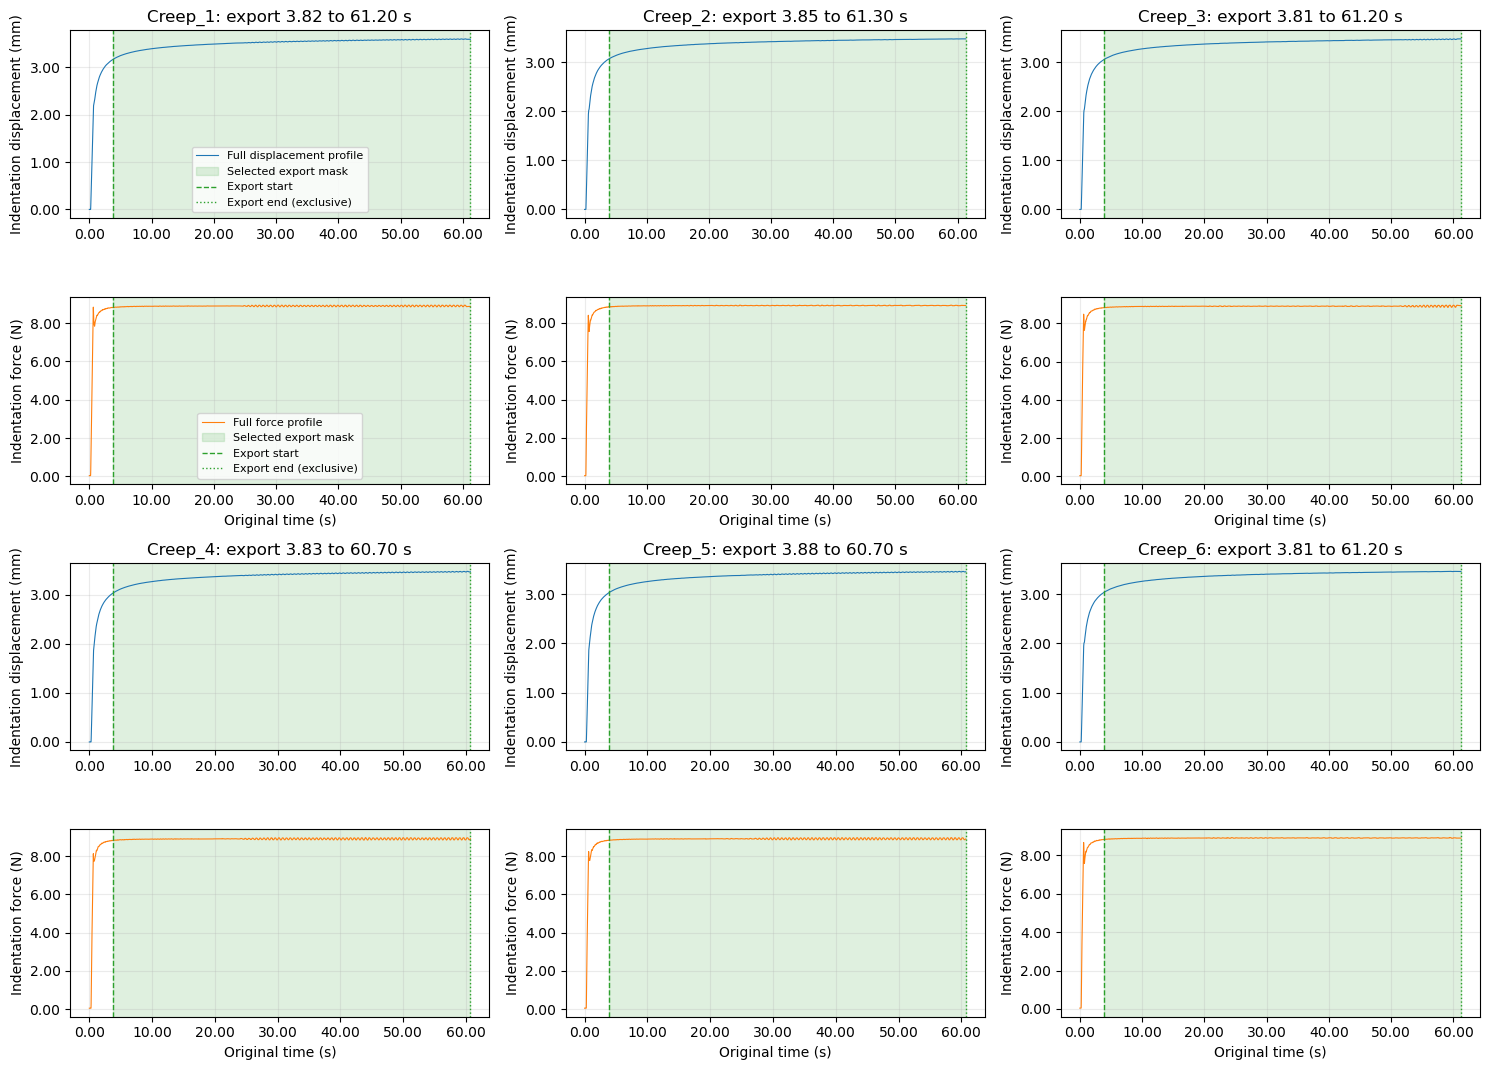

In [15]:
ncols = min(3, len(segmentation_results))
nrows = math.ceil(len(segmentation_results) / ncols)
fig, axes = plt.subplots(2 * nrows, ncols, figsize=(5 * ncols, 5.4 * nrows), squeeze=False)
for index, result in enumerate(segmentation_results):
    row, column = divmod(index, ncols)
    displacement_axis = axes[2 * row, column]
    force_axis = axes[2 * row + 1, column]
    force_axis.sharex(displacement_axis)
    sync = result['sync']
    start, end = result['export_start_s'], result['export_end_s']
    displacement_axis.plot(sync.time_s, sync.displacement_mm, lw=0.8,
                           color='tab:blue', label='Full displacement profile')
    force_axis.plot(sync.time_s, sync.force_n, lw=0.8,
                    color='tab:orange', label='Full force profile')
    displacement_axis.set(title=f"{result['path'].stem}: export {format_fractional_digits(start)} to {format_fractional_digits(end)} s",
                          ylabel='Indentation displacement (mm)')
    force_axis.set(xlabel='Original time (s)', ylabel='Indentation force (N)')
    for axis in (displacement_axis, force_axis):
        axis.axvspan(start, end, color='tab:green', alpha=0.15, label='Selected export mask')
        axis.axvline(start, color='tab:green', ls='--', lw=1, label='Export start')
        axis.axvline(end, color='tab:green', ls=':', lw=1, label='Export end (exclusive)')
        axis.grid(True, alpha=0.25)
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
for index in range(len(segmentation_results), nrows * ncols):
    row, column = divmod(index, ncols)
    axes[2 * row, column].set_visible(False)
    axes[2 * row + 1, column].set_visible(False)
show_figure(fig)


## Inspect retained force and displacement

The comparison below uses only the selected intervals, with time zero at the first retained sample in either mode. Force oscillations are intentionally visible and preserved. No displacement offset is removed, and position and force always retain the same sample count and timestamps.

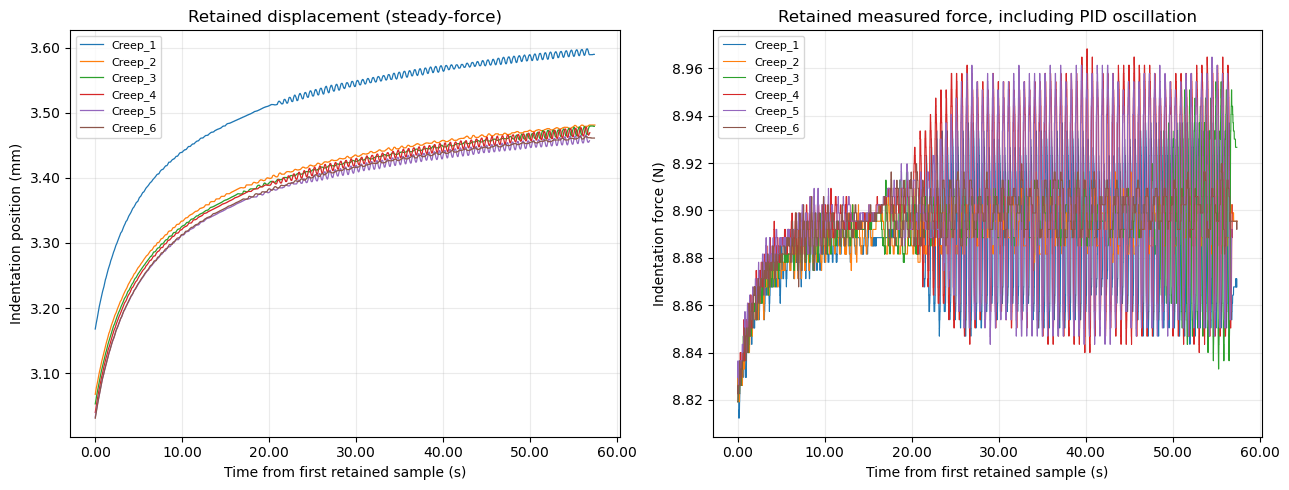

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for txt_path, frame in steady_extracted:
    time = frame[OUTPUT_COLUMNS[0]]
    line, = axes[0].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, label=txt_path.stem)
    axes[1].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, color=line.get_color(), label=txt_path.stem)
axes[0].set(title=f'Retained displacement ({segment_label})', ylabel='Indentation position (mm)')
axes[1].set(title='Retained measured force, including PID oscillation', ylabel='Indentation force (N)')
for axis in axes:
    axis.set_xlabel('Time from first retained sample (s)')
    axis.grid(True, alpha=0.25)
    axis.legend(fontsize=8)
show_figure(fig)

## Export selected intervals

All inputs and selected intervals are validated before writing. Each CSV contains exactly the three configured columns without a row index, with `Time, s` starting at 0 at its first retained sample in either segmentation mode. Running this cell overwrites matching exports and writes `_steady_state_manifest.csv` with the selected mode, original export boundaries (end exclusive), measured variation, and sampling rate. Detected and adjusted steady boundaries, boundary offsets, holding force, and PID detection settings are recorded only when segmentation is enabled. The adjusted `steady_start_s` and `steady_end_s` precede any `EXPORT_DURATION_S` limit; `export_start_s` and `export_end_s` describe the final retained interval. Raw TXT measurements remain untouched.

Steady-only exports start under load. A downstream model that assumes an unloaded initial reference or relaxed viscoelastic states must account for the preceding load history before using these steady-only exports.

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_summary = []
for txt_path, frame in steady_extracted:
    csv_path = OUTPUT_DIR / f'{txt_path.stem}.csv'
    frame.assign(**{column: frame[column]
                    for column in OUTPUT_COLUMNS[1:]}).to_csv(csv_path, index=False)
    export_summary.append({'file': csv_path.name, 'rows': len(frame), 'columns': len(OUTPUT_COLUMNS)})
    print(f'{txt_path.name} -> {csv_path.name}: {len(frame):,} {segment_label} rows x {len(OUTPUT_COLUMNS)} columns')

manifest_path = OUTPUT_DIR / '_steady_state_manifest.csv'
steady_summary.assign(**{column: steady_summary[column]
                         for column in steady_summary.columns if column.endswith(('_n', '_mm'))
                         }).to_csv(manifest_path, index=False)
print(f'\nDone: exported {len(export_summary)} {segment_label} CSV files to {OUTPUT_DIR}')
print(f'Segmentation metadata: {manifest_path.name}')

Creep_1.txt -> Creep_1.csv: 11,476 steady-force rows x 3 columns
Creep_2.txt -> Creep_2.csv: 11,490 steady-force rows x 3 columns
Creep_3.txt -> Creep_3.csv: 11,477 steady-force rows x 3 columns
Creep_4.txt -> Creep_4.csv: 11,373 steady-force rows x 3 columns
Creep_5.txt -> Creep_5.csv: 11,365 steady-force rows x 3 columns
Creep_6.txt -> Creep_6.csv: 11,479 steady-force rows x 3 columns

Done: exported 6 steady-force CSV files to /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data
Segmentation metadata: _steady_state_manifest.csv


## Preview the first 5 rows of the first export

Reuse the selected data in memory; no CSV reread is needed.


In [18]:
display(steady_extracted[0][1].head())


,"Time, s","Indentation Position, mm","Indentation Force, N"
0,0.00,3.17,8.83
1,0.0050,3.17,8.82
2,0.010,3.17,8.82
3,0.015,3.17,8.82
4,0.020,3.17,8.82
